In [ ]:
!pip install -q librosa kagglehub

import os, glob
import numpy as np, pandas as pd
import librosa
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow import keras
from tensorflow.keras import layers

import kagglehub
path = kagglehub.dataset_download("uwrfkaggler/ravdess-emotional-speech-audio")
files = glob.glob(os.path.join(path, "**", "*.wav"), recursive=True)
print("Audio files found:", len(files))

Using Colab cache for faster access to the 'ravdess-emotional-speech-audio' dataset.
Audio files found: 2880


In [ ]:
EMOTIONS = {"01": "neutral", "02": "calm", "03": "happy", "04": "sad",
            "05": "angry", "06": "fearful", "07": "disgust", "08": "surprised"}

df = pd.DataFrame({"path": files})
df["filename"] = df["path"].apply(os.path.basename)
df["emotion"] = df["filename"].apply(lambda f: EMOTIONS[f.split("-")[2]])

print("Files before removing duplicates:", len(df))
print("Duplicate filenames:", df["filename"].duplicated().sum())   # expect 1440

df = df.drop_duplicates(subset="filename").reset_index(drop=True)

print("Shape after:", df.shape)                # expect (1440, 3)
print(df.head())
print(df["emotion"].value_counts())            # expect 192 each, neutral 96

Files before removing duplicates: 2880
Duplicate filenames: 1440
Shape after: (1440, 3)
                                                path  \
0  /kaggle/input/ravdess-emotional-speech-audio/A...   
1  /kaggle/input/ravdess-emotional-speech-audio/A...   
2  /kaggle/input/ravdess-emotional-speech-audio/A...   
3  /kaggle/input/ravdess-emotional-speech-audio/A...   
4  /kaggle/input/ravdess-emotional-speech-audio/A...   

                   filename    emotion  
0  03-01-08-01-01-01-02.wav  surprised  
1  03-01-01-01-01-01-02.wav    neutral  
2  03-01-07-02-01-02-02.wav    disgust  
3  03-01-07-01-01-02-02.wav    disgust  
4  03-01-01-01-02-01-02.wav    neutral  
emotion
surprised    192
disgust      192
fearful      192
sad          192
happy        192
calm         192
angry        192
neutral       96
Name: count, dtype: int64


In [ ]:
def extract_mfcc(file_path):
    y, sr = librosa.load(file_path, duration=3, offset=0.5)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)   # shape: (40, frames)
    return np.mean(mfcc, axis=1)                          # average over time -> 40 numbers

X = np.array([extract_mfcc(p) for p in df["path"]])
print("Features:", X.shape)

Features: (1440, 40)


In [ ]:
class_names = sorted(df["emotion"].unique())
y = df["emotion"].map({c: i for i, c in enumerate(class_names)}).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # learn scaling from training data only
X_test = scaler.transform(X_test)

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(40,)),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(X_train, y_train, validation_split=0.2,
                    epochs=100, batch_size=32,
                    callbacks=[keras.callbacks.EarlyStopping(
                        patience=15, restore_best_weights=True)],
                    verbose=0)

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print("Test loss:", test_loss, "| Test accuracy:", test_acc)
print("Epochs trained:", len(history.history["loss"]))
print("Best epoch:", np.argmin(history.history["val_loss"]) + 1)

Test loss: 1.075947880744934 | Test accuracy: 0.6423611044883728
Epochs trained: 53
Best epoch: 38


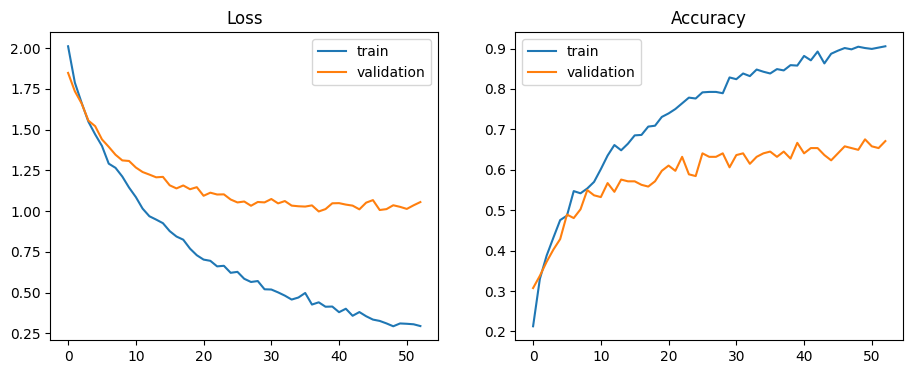

In [ ]:
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy"); plt.legend()
plt.show()

              precision    recall  f1-score   support

       angry       0.79      0.71      0.75        38
        calm       0.76      0.89      0.82        38
     disgust       0.62      0.61      0.61        38
     fearful       0.62      0.82      0.70        39
       happy       0.66      0.54      0.59        39
     neutral       0.62      0.26      0.37        19
         sad       0.55      0.61      0.57        38
   surprised       0.53      0.51      0.52        39

    accuracy                           0.64       288
   macro avg       0.64      0.62      0.62       288
weighted avg       0.64      0.64      0.63       288



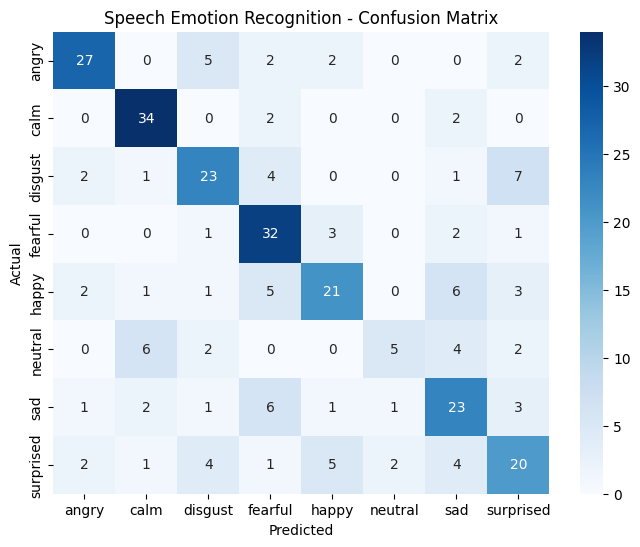

In [ ]:
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Speech Emotion Recognition - Confusion Matrix")
plt.show()